# TP3. Polynômes et fonctions

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp3-polynomes-fonctions/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


**Version complétée avec assistance IA.** Solutions et explications adaptées des [corrigés de Christophe Guyeux](https://cours.gclab.fr/outils-fondamentaux/tp3-polynomes-fonctions/), sous licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). Les blocs du cours nécessaires aux exercices sont ajoutés. Exécuter les cellules dans l’ordre. Les temps mesurés dépendent de la machine. Relire les réponses et indiquer dans le README les vérifications réalisées personnellement.

**Rappel du cours / préparation pour la suite**

In [1]:
P = [2, 3, 0, 5]   

## Exercice 1.1 : évaluation naïve

Écrivez `evaluer_naif(P, x)` qui calcule $P(x)$ en suivant la définition, avec une
puissance par terme.

**Résultat attendu :** `evaluer_naif([2, 3, 0, 5], 2)` vaut `48`, car
$2 + 6 + 40 = 48$.


In [2]:
def evaluer_naif(P, x):

    total = 0
    for i in range(len(P)):
        total = total + P[i] * x ** i
    return total

print(evaluer_naif([2, 3, 0, 5], 2))
print(evaluer_naif([2, 3, 0, 5], 0))

48
2


En x = 0, on retrouve le coefficient constant, 2 : un bon test rapide, car
toute erreur d'indice se voit immédiatement.

## Exercice 2.1 : Horner

Écrivez `evaluer(P, x)` par le schéma de Horner, et vérifiez qu'elle donne le même
résultat que la version naïve sur plusieurs points.

**Résultat attendu :** les deux fonctions coïncident, et Horner est plus rapide sur un
polynôme de degré élevé.


In [3]:
def evaluer(P, x):

    total = 0
    for coefficient in reversed(P):
        total = total * x + coefficient
    return total

P = [2, 3, 0, 5]
for x in (-2, 0, 1, 2, 10):
    print(x, evaluer_naif(P, x), evaluer(P, x))

-2 -44 -44
0 2 2
1 10 10
2 48 48
10 5032 5032


reversed(P) parcourt la liste de la fin vers le début : on commence donc par le
coefficient dominant, et chaque tour multiplie l'accumulateur par x avant
d'ajouter le coefficient suivant. Trois lignes, et c'est optimal : on démontre
qu'aucune méthode ne peut évaluer un polynôme général avec moins de
multiplications.

## Exercice 2.2 : mesurer, et se méfier de ses prévisions

Construisez des polynômes dont tous les coefficients valent 1, de degrés 1 000, 5 000
et 20 000, et comparez le temps des deux méthodes en `x = 1.0001`. Avant de lancer la
mesure, écrivez votre prévision : de combien Horner devrait-il être plus rapide ?

**Résultat attendu :** un rapport d'environ 2, **constant** quand le degré augmente.
Ce n'est probablement pas ce que vous aviez prévu.


**Prévision proposée avant la mesure :** Horner devrait être plus rapide car il évite les puissances. On peut prévoir un gain de quelques fois, sans supposer que ce gain augmente avec le degré en calcul flottant.

In [4]:
import time

for degre in (1000, 5000, 20000):
    P = [1] * (degre + 1)

    debut = time.perf_counter()
    a = evaluer_naif(P, 1.0001)
    t_naif = time.perf_counter() - debut

    debut = time.perf_counter()
    b = evaluer(P, 1.0001)
    t_horner = time.perf_counter() - debut

    print(f"degre {degre:>6} : naif {t_naif:.5f} s | horner {t_horner:.5f} s "
          f"| rapport {t_naif / t_horner:.1f} | ecart des valeurs {abs(a - b):.2e}")

degre   1000 : naif 0.00010 s | horner 0.00004 s | rapport 2.3 | ecart des valeurs 0.00e+00
degre   5000 : naif 0.00047 s | horner 0.00020 s | rapport 2.3 | ecart des valeurs 0.00e+00
degre  20000 : naif 0.00187 s | horner 0.00080 s | rapport 2.3 | ecart des valeurs 7.28e-12


Beaucoup s'attendent à ce que l'écart se creuse avec le degré, en raisonnant ainsi :
la méthode naïve calcule \( x^{i} \) pour chaque terme, donc elle ferait
\( 1 + 2 + \dots + n \) multiplications, soit un coût quadratique. Ce
raisonnement est faux, et la mesure le montre : le rapport reste à 2 environ,
que le degré soit mille ou vingt mille. Les deux méthodes sont donc linéaires.

La raison est que x ** i sur un flottant n'est pas une boucle de i
multiplications : c'est une opération unique, calculée par le processeur à partir
du logarithme et de l'exponentielle, en temps essentiellement constant. La méthode
naïve fait donc \( n \) exponentiations et \( n \) multiplications, Horner fait
\( n \) multiplications et \( n \) additions. D'où un facteur constant, et non
un changement d'ordre de grandeur.

La leçon vaut plus que le résultat : on ne devine pas le coût d'un programme,
on le mesure. Un raisonnement de complexité s'appuie toujours sur des hypothèses
concernant le coût des opérations élémentaires, et ces hypothèses peuvent être
fausses dans le langage que vous utilisez.

Regardez enfin la dernière colonne. Au degré 20 000, les deux méthodes ne donnent
plus tout à fait le même nombre : l'écart est de l'ordre de \( 10^{-12} \).
Accumuler vingt mille puissances de flottants n'est pas la même opération
qu'enchaîner vingt mille multiplications, et chaque arrondi laisse une trace.
Horner est donc, à égalité d'ordre de grandeur, un peu plus rapide et surtout plus
stable numériquement. C'est pour cette dernière raison qu'il est employé partout.

## Exercice 2.3 : le cas où l'écart explose vraiment

Refaites la mesure en évaluant en `x = 3`, un **entier**, sur des degrés 200, 400
et 800. Le rapport reste-t-il constant ?

**Résultat attendu :** cette fois le rapport grandit avec le degré, d'environ 4 à
environ 6.


In [5]:
for degre in (200, 400, 800):
    P = [1] * (degre + 1)

    debut = time.perf_counter()
    a = evaluer_naif(P, 3)
    t_naif = time.perf_counter() - debut

    debut = time.perf_counter()
    b = evaluer(P, 3)
    t_horner = time.perf_counter() - debut

    print(f"degre {degre:>4} : rapport {t_naif / t_horner:.1f} | resultats egaux : {a == b}")

degre  200 : rapport 3.9 | resultats egaux : True
degre  400 : rapport 4.7 | resultats egaux : True
degre  800 : rapport 5.0 | resultats egaux : True


Avec un entier, 3 ** 800 est un nombre de trois cent quatre-vingts chiffres, que
Python calcule exactement, comme au TP1. L'exponentiation n'est plus une opération
à coût constant : elle manipule des entiers de plus en plus grands, et le coût
croît réellement avec le degré. Le raisonnement écarté à l'exercice précédent
redevient valable ici.

Deux mesures, deux conclusions opposées, pour le même code : tout dépend du type
des données. Retenez-le, c'est l'une des différences les plus profondes entre
Python et un langage où un entier fait toujours 64 bits.

Notez enfin que les deux résultats sont exactement égaux cette fois, puisqu'on
ne manipule que des entiers, donc aucun arrondi.

## Exercice 3.1 : la dérivée

Écrivez `deriver(P)` qui renvoie la liste des coefficients du polynôme dérivé.

**Résultat attendu :** `deriver([2, 3, 0, 5])` vaut `[3, 0, 15]`, c'est-à-dire
$3 + 15x^{2}$.


In [6]:
def deriver(P):

    return [i * P[i] for i in range(1, len(P))]

print(deriver([2, 3, 0, 5]))
print(deriver([7]))

[3, 0, 15]
[]


La dérivée d'une constante est le polynôme nul, représenté ici par la liste vide
[]. Vérifiez que votre fonction evaluer renvoie bien 0 sur une liste vide,
sans quoi le cas se propagera en erreur plus loin. Avec le schéma de Horner, c'est
automatique : la boucle ne fait aucun tour et l'accumulateur reste à zéro.

## Exercice 4.1 : dichotomie

Écrivez `dichotomie(f, a, b, tolerance)` qui renvoie une racine de `f` entre `a` et
`b`. Appliquez-la à $x^{2} - 2$ sur $[0, 2]$.

**Résultat attendu :** une valeur proche de $\sqrt{2} \approx 1{,}414214$.


In [7]:
def dichotomie(f, a, b, tolerance=1e-12):

    fa, fb = f(a), f(b)
    if fa == 0:
        return a
    if fb == 0:
        return b
    if fa * fb > 0:
        raise ValueError("f(a) et f(b) doivent etre de signes opposes")
    while b - a > tolerance:
        milieu = (a + b) / 2
        if f(a) * f(milieu) <= 0:
            b = milieu
        else:
            a = milieu
    return (a + b) / 2

def carre_moins_deux(x):
    return x * x - 2

racine = dichotomie(carre_moins_deux, 0, 2)
print(racine)
print(abs(racine - 2 ** 0.5) < 1e-9)

1.414213562372879
True


Le test fa * fb > 0 refuse un intervalle où la méthode n'a aucun sens, plutôt
que de renvoyer un résultat arbitraire. C'est le même réflexe qu'au TP1 avec la
racine carrée d'un nombre négatif : une fonction sérieuse refuse les entrées
qu'elle ne sait pas traiter.

## Exercice 4.2 : Newton sur un polynôme

Écrivez `newton(P, depart, tolerance)` qui cherche une racine du polynôme `P` en
utilisant `evaluer` et `deriver`. Appliquez-la à $x^{3} - 2x - 5$, en partant de 2.

**Résultat attendu :** environ `2.0945515`, atteint en cinq tours ou moins.


In [8]:
def newton(P, depart, tolerance=1e-12, tours_max=100):

    derivee = deriver(P)
    x = float(depart)
    for tour in range(tours_max):
        valeur = evaluer(P, x)
        pente = evaluer(derivee, x)
        if pente == 0:
            raise ZeroDivisionError("tangente horizontale, Newton ne peut pas continuer")
        suivant = x - valeur / pente
        if abs(suivant - x) <= tolerance * max(1.0, abs(suivant)):
            return suivant, tour + 1
        x = suivant
    raise RuntimeError("pas de convergence en {} tours".format(tours_max))


Q = [-5, -2, 0, 1]
racine, tours = newton(Q, 2)
print(racine, "en", tours, "tours")
print(abs(evaluer(Q, racine)) < 1e-10)

2.0945514815423265 en 5 tours
True


Trois protections méritent d'être remarquées. La tangente horizontale est
détectée au lieu de provoquer une division par zéro incompréhensible. Le nombre
de tours est plafonné, sans quoi une divergence donnerait une boucle infinie. Et
le critère d'arrêt est relatif, comme au TP1.

## Exercice 4.3 : faire échouer Newton

Appliquez `newton` au polynôme $x^{3} - 2x + 2$, c'est-à-dire `[2, -2, 0, 1]`, en
partant de `0`. Affichez le trajet des premiers itérés pour comprendre ce qui se passe.

**Résultat attendu :** aucune convergence, et un trajet qui alterne entre `0` et `1`
indéfiniment.


In [9]:
def newton_trace(P, depart, tours):

    derivee = deriver(P)
    x = float(depart)
    trajet = [x]
    for _ in range(tours):
        pente = evaluer(derivee, x)
        if pente == 0:
            break
        x = x - evaluer(P, x) / pente
        trajet.append(x)
    return trajet

R = [2, -2, 0, 1]          
print(newton_trace(R, 0, 8))

try:
    print(newton(R, 0))
except RuntimeError as erreur:
    print("echec :", erreur)

[0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0]
echec : pas de convergence en 100 tours


Le trajet est [0.0, 1.0, 0.0, 1.0, 0.0, 1.0, ...] : la tangente en 0 renvoie en
1, celle en 1 renvoie en 0, et la méthode tourne en rond pour toujours. On parle
d'un cycle de la méthode de Newton. Sans le plafond tours_max que nous avons
mis dans la fonction, votre programme ne s'arrêterait jamais, et c'est là toute
l'utilité de ce garde-fou.

Essayez aussi de partir de math.sqrt(2 / 3) sur le polynôme
\( x^{3} - 2x - 5 \) de l'exercice précédent : c'est un point où la dérivée
s'annule, la tangente est presque horizontale, et le premier pas projette le
calcul à environ \( -2{,}7 \times 10^{16} \). La méthode met ensuite des
dizaines de tours à revenir, sans converger dans le budget imparti.

## Exercice 4.4 : le prix d'un mauvais point de départ

Reprenez $x^{3} - 2x - 5$ et comparez le nombre de tours de `newton` en partant
de `2`, puis de `0`.

**Résultat attendu :** cinq tours depuis `2`, une vingtaine depuis `0`.


In [10]:
Q = [-5, -2, 0, 1]
for depart in (2, 1, 0):
    racine, tours = newton(Q, depart)
    print(f"depart {depart:>2} : {tours:>2} tours, racine {racine:.9f}")

depart  2 :  5 tours, racine 2.094551482
depart  1 : 10 tours, racine 2.094551482
depart  0 : 20 tours, racine 2.094551482


Les trois appels trouvent la même racine, donc les trois sont « justes ». Mais
depuis 0, la méthode commence par s'éloigner, passe par -2.5, -1.57,
-3.82, erre un moment, puis finit par tomber dans la zone où la convergence
quadratique s'enclenche. Newton n'est rapide que près de la racine : loin
d'elle, son comportement n'a aucune garantie.

C'est pourquoi, en pratique, on encadre d'abord la racine par quelques
dichotomies avant de passer à Newton. Les bibliothèques sérieuses, comme
scipy.optimize.brentq, font exactement cela.

**Rappel du cours / préparation pour la suite**

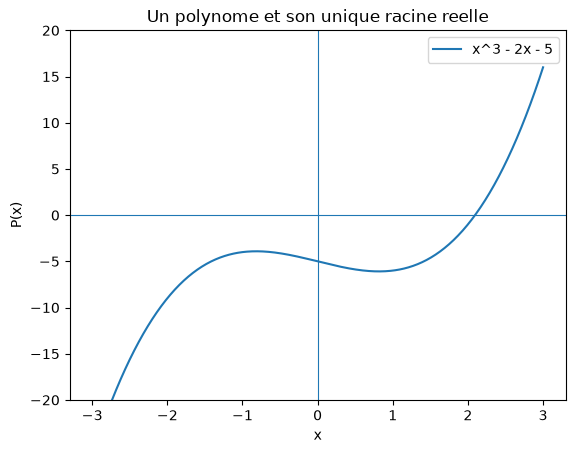

In [11]:
import matplotlib.pyplot as plt

Q = [-5, -2, 0, 1]          
xs = [i / 100 for i in range(-300, 301)]
ys = [evaluer(Q, x) for x in xs]

plt.figure()
plt.plot(xs, ys, label="x^3 - 2x - 5")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.ylim(-20, 20)
plt.xlabel("x")
plt.ylabel("P(x)")
plt.legend()
plt.title("Un polynome et son unique racine reelle")
plt.show()

## Exercice 5.1 : lire le graphique

Sur le tracé, repérez la racine trouvée par Newton. Combien de fois la courbe
coupe-t-elle l'axe des abscisses ? Ce polynôme est de degré 3 : que dire de ses autres
racines ?


La courbe ne coupe l'axe qu'une seule fois, près de 2.0945. Un polynôme de
degré 3 possède toujours trois racines dans les nombres complexes ; ici les deux
autres sont complexes conjuguées, donc invisibles sur un tracé réel. Un graphique
montre ce qui existe dans les réels, jamais ce qui n'y est pas : c'est une limite
à connaître avant de conclure « il n'y a pas d'autre solution ».

## Exercice 6.1 : somme et produit

Écrivez `somme(P, Q)` et `produit_poly(P, Q)`. Attention, les deux listes n'ont pas
forcément la même longueur.

**Résultat attendu :** `produit_poly([1, 1], [1, 1])` vaut `[1, 2, 1]`, c'est-à-dire
$(1 + x)^{2} = 1 + 2x + x^{2}$, et `produit_poly([-1, 1], [1, 1])` vaut
`[-1, 0, 1]`, l'identité $(x - 1)(x + 1) = x^{2} - 1$.


In [12]:
def somme(P, Q):

    longueur = max(len(P), len(Q))
    P = P + [0] * (longueur - len(P))
    Q = Q + [0] * (longueur - len(Q))
    return [P[i] + Q[i] for i in range(longueur)]

def produit_poly(P, Q):

    if not P or not Q:
        return []
    R = [0] * (len(P) + len(Q) - 1)
    for i in range(len(P)):
        for j in range(len(Q)):
            R[i + j] = R[i + j] + P[i] * Q[j]
    return R

print(somme([1, 2], [0, 0, 3]))
print(produit_poly([1, 1], [1, 1]))
print(produit_poly([-1, 1], [1, 1]))

[1, 2, 3]
[1, 2, 1]
[-1, 0, 1]


Le degré du produit est la somme des degrés, d'où la longueur
len(P) + len(Q) - 1. Vérifiez la fonction autrement qu'en lisant le résultat :
évaluez P, Q et leur produit en un même point, et contrôlez que
evaluer(produit_poly(P, Q), x) vaut evaluer(P, x) * evaluer(Q, x). C'est le
même réflexe que la vérification de la division euclidienne au TP1.

## Exercice 6.2 : le triangle de Pascal, par les polynômes

Calculez $(1 + x)^{10}$ en multipliant dix fois `[1, 1]` par lui-même. Que
reconnaissez-vous dans la liste obtenue ?

**Résultat attendu :** `[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]`.


In [13]:
binome = [1]
for _ in range(10):
    binome = produit_poly(binome, [1, 1])
print(binome)
print(sum(binome), 2 ** 10)

[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]
1024 1024


Ce sont les coefficients binomiaux \( \binom{10}{k} \), la dixième ligne du
triangle de Pascal. Leur somme vaut \( 2^{10} \), ce qui est la formule du binôme
évaluée en \( x = 1 \). Une identité algébrique que vous avez apprise par cœur
devient ici une vérification en deux lignes.

## Exercice 7.1 : trouver le meilleur pas

Écrivez `derivee_avant(f, x, h)` et `derivee_centree(f, x, h)`. Calculez l'erreur de
chacune sur $\sin$ en $x = 1$, dont la dérivée exacte est $\cos 1$, pour
`h` valant $10^{-1}, 10^{-2}, 10^{-4}, 10^{-6}, 10^{-8}, 10^{-10}, 10^{-12}$.

**Résultat attendu :** l'erreur diminue puis **remonte**. Le meilleur pas est de
l'ordre de $10^{-8}$ pour la formule avant, $10^{-6}$ pour la formule centrée,
et à $h = 10^{-12}$ l'erreur est remontée de quatre à six ordres de grandeur
par rapport à ce meilleur pas.


In [14]:
import math

def derivee_avant(f, x, h):
    return (f(x + h) - f(x)) / h

def derivee_centree(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

exacte = math.cos(1.0)
for h in (1e-1, 1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12):
    e_avant = abs(derivee_avant(math.sin, 1.0, h) - exacte)
    e_centree = abs(derivee_centree(math.sin, 1.0, h) - exacte)
    print(f"h = {h:.0e} : avant {e_avant:.1e} | centree {e_centree:.1e}")

h = 1e-01 : avant 4.3e-02 | centree 9.0e-04
h = 1e-02 : avant 4.2e-03 | centree 9.0e-06
h = 1e-04 : avant 4.2e-05 | centree 9.0e-10
h = 1e-06 : avant 4.2e-07 | centree 2.8e-11
h = 1e-08 : avant 3.0e-09 | centree 2.6e-09
h = 1e-10 : avant 5.8e-08 | centree 5.8e-08
h = 1e-12 : avant 4.3e-05 | centree 1.2e-05


Deux erreurs se disputent le résultat. L'erreur de méthode, due au fait qu'un
taux de variation n'est pas une dérivée, diminue avec \( h \) : proportionnelle à
\( h \) pour la formule avant, à \( h^{2} \) pour la formule centrée, ce qui se
lit dans les premières lignes, où l'erreur centrée perd deux zéros quand h en
perd un. L'erreur d'arrondi, due à la soustraction de deux valeurs presque
égales, est celle de l'exercice 7.1 du TP1 : elle vaut environ
\( 10^{-16} / h \) et grandit quand \( h \) diminue. Le meilleur pas est celui
où les deux se croisent.

La formule centrée est meilleure sur toute la ligne : à même coût, deux
évaluations de \( f \), elle gagne quatre à cinq chiffres. Retenez-la, et retenez
surtout qu'en calcul numérique « plus fin » ne veut pas dire « plus juste ».

## Exercice 8.1 : les trois méthodes

Écrivez `rectangles(f, a, b, n)`, `trapezes(f, a, b, n)` et `simpson(f, a, b, n)`.
Testez-les sur $\int_0^1 x^{2}\,dx = 1/3$ pour `n` valant 10, 100 et 1000.

**Résultat attendu :** l'erreur des rectangles est divisée par 10 quand `n` est
multiplié par 10, celle des trapèzes par 100, et Simpson donne le résultat exact, à
un arrondi de $10^{-17}$ près.


In [15]:
def rectangles(f, a, b, n):

    h = (b - a) / n
    return h * sum(f(a + i * h) for i in range(n))

def trapezes(f, a, b, n):

    h = (b - a) / n
    interieur = sum(f(a + i * h) for i in range(1, n))
    return h * ((f(a) + f(b)) / 2 + interieur)

def simpson(f, a, b, n):

    if n % 2 == 1:
        n = n + 1
    h = (b - a) / n
    impairs = sum(f(a + i * h) for i in range(1, n, 2))
    pairs = sum(f(a + i * h) for i in range(2, n, 2))
    return h / 3 * (f(a) + f(b) + 4 * impairs + 2 * pairs)

def carre(x):
    return x * x

for n in (10, 100, 1000):
    e_rect = abs(rectangles(carre, 0, 1, n) - 1 / 3)
    e_trap = abs(trapezes(carre, 0, 1, n) - 1 / 3)
    e_simp = abs(simpson(carre, 0, 1, n) - 1 / 3)
    print(f"n = {n:>4} : rectangles {e_rect:.1e} | trapezes {e_trap:.1e} | simpson {e_simp:.1e}")

n =   10 : rectangles 4.8e-02 | trapezes 1.7e-03 | simpson 0.0e+00
n =  100 : rectangles 5.0e-03 | trapezes 1.7e-05 | simpson 5.6e-17
n = 1000 : rectangles 5.0e-04 | trapezes 1.7e-07 | simpson 0.0e+00


On dit que les rectangles sont d'ordre 1, les trapèzes d'ordre 2 : l'erreur
est proportionnelle à \( h \), puis à \( h^{2} \). Simpson est d'ordre 4, et il
est même exact sur tout polynôme de degré au plus 3, ce qui explique le zéro
de la dernière colonne. Pour le voir travailler, essayez une fonction qui n'est
pas un polynôme : \( \int_0^{\pi} \sin x\,dx = 2 \), où l'erreur de Simpson est
divisée par \( 10^{4} \) chaque fois que n est multiplié par 10.

## Exercice 8.2 : calculer π

On a $\int_0^1 \frac{4}{1 + x^{2}}\,dx = \pi$. Calculez cette intégrale par les
trapèzes et par Simpson avec `n = 1000`, et comparez à `math.pi`.

**Résultat attendu :** une erreur de l'ordre de $10^{-7}$ pour les trapèzes, et
un résultat indistinguable de `math.pi` pour Simpson.


In [16]:
def arctangente_derivee(x):
    return 4 / (1 + x * x)

approx_trap = trapezes(arctangente_derivee, 0, 1, 1000)
approx_simp = simpson(arctangente_derivee, 0, 1, 1000)
print(approx_trap, abs(approx_trap - math.pi))
print(approx_simp, abs(approx_simp - math.pi))

3.141592486923127 1.6666666624587378e-07
3.141592653589793 0.0


Mille évaluations d'une fraction, et l'on obtient toutes les décimales de π que
la machine sait écrire. Avec les rectangles, il en faudrait des milliards. Comme
au TP2, changer de méthode rapporte infiniment plus qu'augmenter n.

**Note de lecture :** les commentaires du corrigé donnent des ordres de grandeur. Pour les durées et les erreurs numériques, les sorties enregistrées dans ce carnet sont les mesures de cette exécution ; elles peuvent varier en relançant le carnet.